# DEMAE Phase-D — corpus visualization

This notebook renders the **selection the sampler drew** — the 50,000 windows
Phase E will materialize into the debug-tier corpus — so the ADR-0004 pipeline is
auditable at a glance:

1. **The strata** — what k-means found in the frozen six metrics, read back in raw
   metric units (the `centroids.json` artifact).
2. **Occupancy and allocation** — how many kept windows each stratum holds (`N_h`)
   and how many the Neyman rule buys from it (`n_h`), re-derived here from the
   committed table by the live `dataset.select.allocate`.
3. **The selection list** — realized picks per stratum, the coastal reservation,
   the windows-per-COG distribution, and where the 50k land on the globe.
4. **The read path** — sampled tiles and before/after per-tile normalization,
   driven through `dataset.loader` over a small locally-built shard fixture.

**Zero network required, and no corpus required.** Sections 1–3 read only files
that are committed to this repo (`artifacts/phase_d/*`, `docs/research/d4-selection.json`);
section 4 builds its own 9-tile fixture in a scratch directory. Nothing here reads
S3, and nothing here needs `data/catalog_gated/`.

> **Where this sits in the pipeline.** `dataset.catalog` → `dataset.gates` →
> `dataset.frame` (the scaler) → `dataset.centroids` (k=20) → `dataset.select`
> (allocate + FSCS → the selection list). The end-to-end **materialize** — turning
> the selection list into `shards/` + `manifest.parquet` — is Phase E and is not
> built yet, which is why section 4 constructs its fixture from the ADR-0002
> storage primitives directly rather than running a build CLI.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyarrow.csv as pacsv

plt.rcParams["figure.dpi"] = 70  # keep committed inline PNGs light

from dataset import centroids as centroids_mod
from dataset import frame as frame_mod
from dataset import select as select_mod

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ARTIFACTS = REPO / "artifacts" / "phase_d"
RESEARCH = REPO / "docs" / "research"

scaler = frame_mod.read_scaler(ARTIFACTS / "scaler.json")
centroids = centroids_mod.read_centroids(ARTIFACTS / "centroids.json")
d4 = json.loads((RESEARCH / "d4-selection.json").read_text())

METRICS = frame_mod.METRICS
LOG_METRICS = frame_mod.LOG_METRICS

# The one audit that has to pass before any figure below means anything: all three
# artifacts must describe the *same* frame. Each carries the fingerprint of the frame
# it was fitted over (row count, gate thresholds, catalog code_version) precisely so a
# mismatch is loud rather than plausible-looking.
assert scaler.fingerprint == centroids.fingerprint == d4["frame_fingerprint"], (
    "scaler / centroids / selection were built over different frames"
)
fp = scaler.fingerprint

print(f"frame:      {fp['n_kept']:,} kept windows  (catalog code_version {fp['catalog_code_version']})")
print(f"strata:     k = {centroids.k}  ({centroids.provenance['implementation']}, "
      f"n_init={centroids.provenance['n_init']}, inertia {centroids.provenance['inertia']:,.0f})")
print(f"selection:  {d4['n_selected']:,} windows at budget {d4['budget']:,}  "
      f"over {d4['per_cog']['n_cogs']:,} COGs")
print(f"metrics:    {', '.join(m + ' (log)' if m in LOG_METRICS else m for m in METRICS)}")

frame:      3,052,735 kept windows  (catalog code_version ad46e96)
strata:     k = 20  (scikit-learn KMeans, n_init=25, inertia 3,596,296)
selection:  50,000 windows at budget 50,000  over 15,834 COGs
metrics:    slope_mean (log), local_relief (log), texture, elevation_relief_ratio, mean_elevation, geomorphon_entropy


## 1 — The strata: what k-means found

Stratification is **k-means over the frozen six**, not TRI quintiles. There is no
single "ruggedness" axis to cut into equal bins any more: a stratum is a region of a
six-dimensional descriptor space, and `centroids.json` is the shipped list of its 20
centres. Assignment is a pure `argmin` against those centres
(`dataset.centroids.assign`), which is what makes a window's stratum reproducible on
any machine without re-fitting.

The centroids are stored in **standardized space** (z-scored after ADR-0004's two
`ln(x+1)` transforms), which is the space the k-means distance actually runs in — so the
heatmap is the honest picture of how far apart the strata are. The table printed under
it undoes the scaler and the logs to put the same centres back into the units each
metric was measured in, which is the readable picture of *what terrain* a stratum is:
stratum 5 is a near-flat plain at 27 m of local relief, stratum 19 an alpine ridge at
981 m, stratum 6 a high plateau (4,545 m mean elevation) that is barely sloped at all.

Strata are ordered by centroid `slope_mean` throughout this notebook — smooth at the
top, rugged at the bottom — so every figure shares one axis. The ids on the axis are
the real `stratum_id`s; the ordering is presentation only.

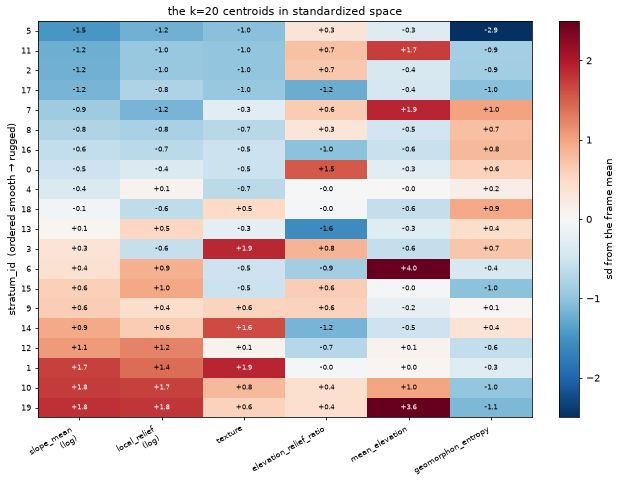

  h │   slope mean local relief      textureelevation relief ratiomean elevationgeomorphon entropy
────┼──────────────────────────────────────────────────────────────────────────────
  5 │         0.6°         27 m        0.002         0.47        511 m    0.75 bits
 11 │         0.9°         36 m        0.011         0.53       2429 m    1.88 bits
  2 │         0.9°         36 m        0.010         0.52        437 m    1.88 bits
 17 │         1.0°         45 m        0.015         0.27        417 m    1.78 bits
  7 │         1.5°         28 m        0.109         0.51       2592 m    2.93 bits
  8 │         1.7°         43 m        0.050         0.47        362 m    2.78 bits
 16 │         2.1°         52 m        0.072         0.30        286 m    2.82 bits
  0 │         2.3°         75 m        0.071         0.63        548 m    2.69 bits
  4 │         2.8°        127 m        0.053         0.43        811 m    2.46 bits
 18 │         3.8°         54 m        0.213         0.43    

In [2]:
Z_C = centroids.centers  # (k, 6) standardized
ORDER = np.argsort(Z_C[:, METRICS.index("slope_mean")])  # smooth -> rugged, presentation only
ORDER_LABELS = [str(h) for h in ORDER]

# Undo the scaler, then undo ADR-0004's ln(x+1) on the two log metrics, to read a
# centroid back in the units the metric was measured in.
raw_centers = scaler.mean + Z_C * scaler.std
for j, name in enumerate(METRICS):
    if name in LOG_METRICS:
        raw_centers[:, j] = np.expm1(raw_centers[:, j])

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(Z_C[ORDER], cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(METRICS)))
ax.set_xticklabels([m + "\n(log)" if m in LOG_METRICS else m for m in METRICS],
                   rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(centroids.k))
ax.set_yticklabels(ORDER_LABELS, fontsize=8)
ax.set_ylabel("stratum_id  (ordered smooth → rugged)")
ax.set_title(f"the k={centroids.k} centroids in standardized space", fontsize=11)
for r, h in enumerate(ORDER):
    for c in range(len(METRICS)):
        v = Z_C[h, c]
        ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 1.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, label="sd from the frame mean")
fig.tight_layout()
plt.show()

# The same centres in raw units. Printed rather than plotted: the six columns differ by
# orders of magnitude in scale and in unit, so a shared colour scale would say nothing.
UNITS = {"slope_mean": "°", "local_relief": " m", "texture": "", "elevation_relief_ratio": "",
         "mean_elevation": " m", "geomorphon_entropy": " bits"}
FMT = {"slope_mean": "{:.1f}", "local_relief": "{:.0f}", "texture": "{:.3f}",
       "elevation_relief_ratio": "{:.2f}", "mean_elevation": "{:.0f}",
       "geomorphon_entropy": "{:.2f}"}
WIDTH = 13
head = "  h │" + "".join(f"{m.replace('_', ' '):>{WIDTH}}" for m in METRICS)
print(head)
print("────┼" + "─" * (WIDTH * len(METRICS)))
for h in ORDER:
    row_cells = "".join(f"{FMT[m].format(raw_centers[h, j]) + UNITS[m]:>{WIDTH}}"
                        for j, m in enumerate(METRICS))
    print(f"{h:>3} │{row_cells}")

## 2 — Occupancy and allocation

Two numbers per stratum decide how much of the budget it gets:

- **`N_h`** — how many of the 3,052,735 kept windows land in it. k-means over a
  continuum does not produce equal bins, and this is the panel that shows it: the
  biggest stratum holds several times what the smallest does. (The retired TRI
  stratifier gave equal quotas by construction, because it cut quintiles.)
- **`σ_h`** — the mean distance of a stratum's rows to its own centroid, in sd units.
  Internally varied strata score higher and are worth more samples.

The rule is **pure Neyman**, `n_h ∝ N_h·σ_h`, apportioned to the exact budget by
largest-remainder, with a within-stratum **coastal reservation** of 670 windows
(1.34% of budget — the coastline rate of the kept frame itself, so coast is never
*under*-represented). The `max(500, 1%·budget)` floor clamp is measured inert at every
budget and is reported, never applied.

The cell below plots the **shipped** table — that is the contract — and then feeds the
committed `N_h`, `σ_h`, `coast_h` back through the live `dataset.select.allocate` as an
audit that today's code still produces it. The audit's tolerance is one window per
stratum, and the reason is worth knowing: the JSON records `σ_h` rounded to four
decimals, and largest-remainder apportionment is decided at the remainder boundary, so
a few strata trade a single window against the full-precision run. The budget total and
the coastal reservation are exact either way.

shipped table: Σn_h = 50,000 = budget, Σc_h = 670 = coastal floor
live allocate() re-derives it from the rounded σ_h: 4/20 strata differ, by at most 1 window; c_h identical
floor clamp 500 would fire on 0/20 strata (reported, never applied)


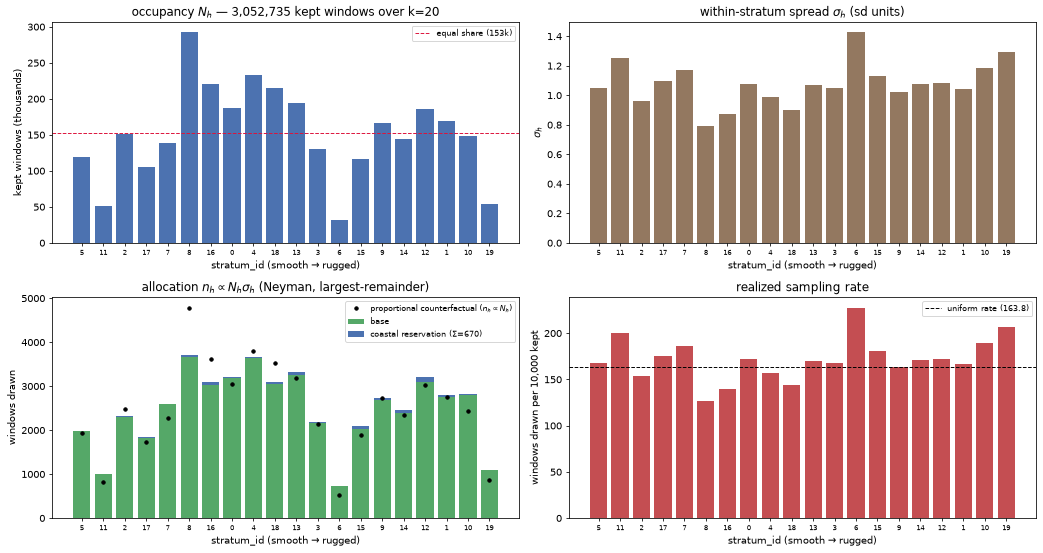

In [3]:
rows = d4["allocation"]
N_h = np.array([r["N_h"] for r in rows], dtype=np.int64)
sigma_h = np.array([r["sigma_h"] for r in rows], dtype=np.float64)
coast_h = np.array([r["coast_h"] for r in rows], dtype=np.int64)
n_h = np.array([r["n_h"] for r in rows], dtype=np.int64)
coastal_h = np.array([r["coastal"] for r in rows], dtype=np.int64)
base_h = np.array([r["base"] for r in rows], dtype=np.int64)
BUDGET, K = d4["budget"], d4["k"]

assert n_h.sum() == BUDGET and coastal_h.sum() == d4["coast_floor"]
assert np.array_equal(base_h + coastal_h, n_h)

alloc = select_mod.allocate(N_h, sigma_h, coast_h, BUDGET)  # the audit, from rounded inputs
drift = np.abs(alloc.n_h - n_h)
assert drift.max() <= 1 and alloc.n_h.sum() == BUDGET, "allocate() no longer reproduces the table"
assert np.array_equal(alloc.coastal, coastal_h)
print(f"shipped table: Σn_h = {n_h.sum():,} = budget, Σc_h = {coastal_h.sum()} = coastal floor")
print(f"live allocate() re-derives it from the rounded σ_h: {int((drift > 0).sum())}/{K} strata "
      f"differ, by at most {int(drift.max())} window; c_h identical")
print(f"floor clamp {alloc.floor_clamp} would fire on "
      f"{alloc.floor_clamp_strata_below}/{K} strata (reported, never applied)")

# What Neyman buys over the naive alternative: a purely proportional draw, n_h ∝ N_h.
proportional = N_h / N_h.sum() * BUDGET
x = np.arange(K)

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
(a_occ, a_sig), (a_alloc, a_rate) = axes

a_occ.bar(x, N_h[ORDER] / 1e3, color="#4c72b0")
a_occ.axhline(N_h.mean() / 1e3, color="crimson", ls="--", lw=1,
              label=f"equal share ({N_h.mean()/1e3:,.0f}k)")
a_occ.set(title=f"occupancy $N_h$ — {N_h.sum():,} kept windows over k={K}",
          ylabel="kept windows (thousands)")
a_occ.legend(fontsize=8)

a_sig.bar(x, sigma_h[ORDER], color="#937860")
a_sig.set(title=r"within-stratum spread $\sigma_h$ (sd units)", ylabel=r"$\sigma_h$")

a_alloc.bar(x, base_h[ORDER], color="#55a868", label="base")
a_alloc.bar(x, coastal_h[ORDER], bottom=base_h[ORDER], color="#4c72b0",
            label=f"coastal reservation (Σ={coastal_h.sum()})")
a_alloc.plot(x, proportional[ORDER], "k.", ms=7, label=r"proportional counterfactual ($n_h \propto N_h$)")
a_alloc.set(title=r"allocation $n_h \propto N_h\sigma_h$ (Neyman, largest-remainder)",
            ylabel="windows drawn")
a_alloc.legend(fontsize=8)

a_rate.bar(x, n_h[ORDER] / N_h[ORDER] * 1e4, color="#c44e52")
a_rate.axhline(BUDGET / N_h.sum() * 1e4, color="black", ls="--", lw=1,
               label=f"uniform rate ({BUDGET / N_h.sum() * 1e4:.1f})")
a_rate.set(title="realized sampling rate", ylabel="windows drawn per 10,000 kept")
a_rate.legend(fontsize=8)

for ax in axes.ravel():
    ax.set_xticks(x)
    ax.set_xticklabels(ORDER_LABELS, fontsize=7)
    ax.set_xlabel("stratum_id (smooth → rugged)")

fig.tight_layout()
plt.show()

## 3 — The selection list

`artifacts/phase_d/selection_debug_50k.csv` is the **contract**: 50,000
`window_id, stratum_id, provenance` rows, sorted, committed, and re-loaded by Phase E
rather than regenerated. The sampler's within-stratum rule is FSCS — sub-k-means at
`k = n_h`, take the window nearest each sub-centroid, geo-cell round-robin as the
tie-break — run twice per stratum: once over the stratum's coastal rows for its `c_h`
reserved picks (`provenance = floor:coastline`), once over the rest (`base`).

So `provenance` records *which draw bought a window*. The asserts below are the check
that the list on disk is the list the allocation asked for — a per-stratum bar chart of
it would just redraw the allocation panel above — and the two panels show the parts of
the draw the allocation table cannot: how wide the round-robin spread each stratum's
picks, and where the coastal reservation actually went.

50,000 rows, all window_ids unique; per-stratum counts and coastal picks match the allocation exactly
provenance: base 49,330, floor:coastline 670
the selection touches 400 distinct 10° geo-cells; a single stratum's draw reaches between 41 (stratum 6) and 326 (stratum 0) of them


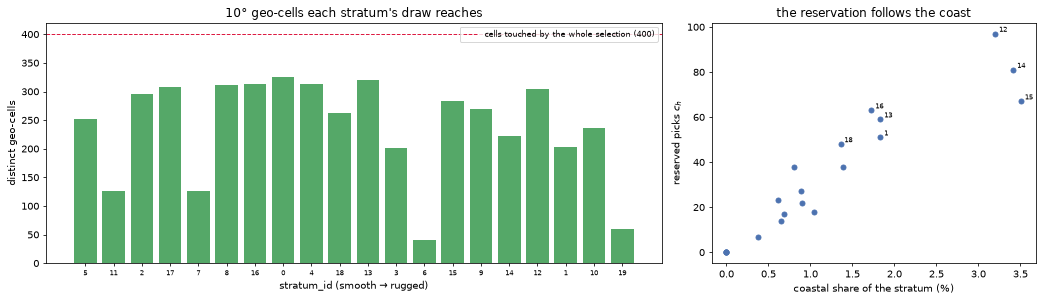

In [4]:
from dataset import geometry

sel = pacsv.read_csv(ARTIFACTS / "selection_debug_50k.csv")
sel_stratum = sel.column("stratum_id").to_numpy()
sel_prov = np.array(sel.column("provenance").to_pylist(), dtype=object)
sel_window = np.array(sel.column("window_id").to_pylist(), dtype=object)

realized = np.bincount(sel_stratum, minlength=K)
realized_coastal = np.bincount(sel_stratum[sel_prov == select_mod.PROV_COASTLINE],
                               minlength=K)

assert sel.num_rows == d4["n_selected"] == BUDGET
assert np.array_equal(realized, n_h), "the list on disk does not match the allocation"
assert np.array_equal(realized_coastal, coastal_h), "provenance does not match the reservation"
assert len(set(sel_window.tolist())) == sel.num_rows, "duplicate window_id in the selection"
print(f"{sel.num_rows:,} rows, all window_ids unique; "
      "per-stratum counts and coastal picks match the allocation exactly")
print("provenance:", ", ".join(f"{k} {v:,}" for k, v in d4["provenance_counts"].items()))

# A window_id is `<cog stem>:<win_row0>:<win_col0>`, and the stem encodes the 1°
# south-west corner of its COG — so geography is recoverable from the list alone, with no
# catalog. One parse per unique stem, then a lookup per window.
stems = np.array([w.rsplit(":", 2)[0] for w in sel_window], dtype=object)
uniq_stems, per_cog = np.unique(stems, return_counts=True)
stem_lonlat = {}
stem_cell = {}
for s in uniq_stems:
    ref = geometry.parse_cog_key(s)
    stem_lonlat[s] = (ref.origin_lon + 0.5, ref.origin_lat + 0.5)  # centre of the 1° cell
    stem_cell[s] = geometry.geocell_id(*stem_lonlat[s])            # the 10° round-robin cell
cells = np.array([stem_cell[s] for s in stems], dtype=object)
cells_total = len(set(cells.tolist()))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.4),
                               gridspec_kw={"width_ratios": [1.9, 1.0]})

# The FSCS tie-break is a geo-cell round-robin, so a stratum's picks should be spread
# across cells rather than clumped where its terrain is densest.
per_stratum_cells = np.array([len(set(cells[sel_stratum == h].tolist())) for h in range(K)])
ax0.bar(x, per_stratum_cells[ORDER], color="#55a868")
ax0.axhline(cells_total, color="crimson", ls="--", lw=1,
            label=f"cells touched by the whole selection ({cells_total})")
ax0.set_xticks(x); ax0.set_xticklabels(ORDER_LABELS, fontsize=7)
ax0.set(title="10° geo-cells each stratum's draw reaches",
        xlabel="stratum_id (smooth → rugged)", ylabel="distinct geo-cells")
ax0.legend(fontsize=8)
print(f"the selection touches {cells_total} distinct 10° geo-cells; a single stratum's draw "
      f"reaches between {per_stratum_cells.min()} (stratum {int(per_stratum_cells.argmin())}) "
      f"and {per_stratum_cells.max()} (stratum {int(per_stratum_cells.argmax())}) of them")

# The coastal reservation is *within-stratum*: c_h follows each stratum's own coastal
# population, so it lands where the coast actually is rather than being spread evenly.
ax1.scatter(coast_h / N_h * 100, coastal_h, s=26, color="#4c72b0")
ax1.set(title="the reservation follows the coast",
        xlabel="coastal share of the stratum (%)", ylabel=r"reserved picks $c_h$")
for h in range(K):
    if coastal_h[h] >= 40 or coast_h[h] / N_h[h] > 0.04:
        ax1.annotate(str(h), (coast_h[h] / N_h[h] * 100, coastal_h[h]),
                     fontsize=7, xytext=(4, 2), textcoords="offset points")

fig.tight_layout()
plt.show()

### Windows per source COG

ADR-0001's `PER_TILE_WINDOW_CAP` was retired as **inert** at the debug tier (#42): the
sampler averages ~3 windows per 1° COG, nowhere near the untested cap of 64. But #42
binds the sampler to *measure* the distribution at every tier, so Phase F can decide
on evidence whether the denser 200–500k tier needs a cap reintroduced. This is that
measurement, recomputed here from the list rather than quoted from the summary.

15,834 COGs — mean 3.16, median 2, p99 16, max 44 windows/COG


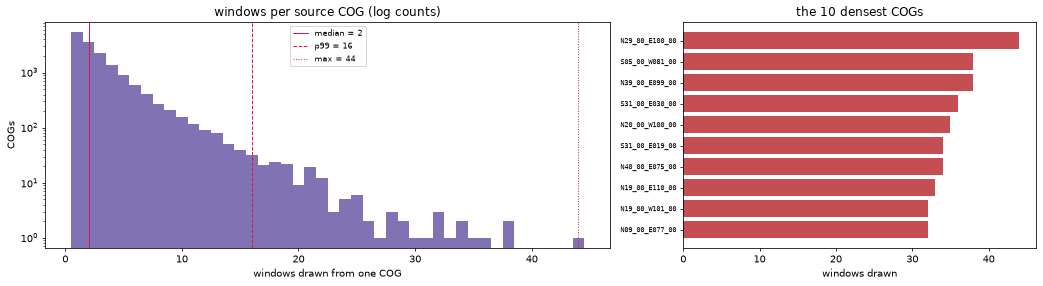

In [5]:
pc = d4["per_cog"]
assert len(uniq_stems) == pc["n_cogs"] and int(per_cog.max()) == pc["max_per_cog"]
print(f"{len(uniq_stems):,} COGs — mean {per_cog.mean():.2f}, median {np.median(per_cog):.0f}, "
      f"p99 {np.percentile(per_cog, 99):.0f}, max {per_cog.max()} windows/COG")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 4.2),
                               gridspec_kw={"width_ratios": [1.6, 1.0]})

bins = np.arange(0.5, per_cog.max() + 1.5)
ax0.hist(per_cog, bins=bins, color="#8172b3")
ax0.set_yscale("log")
for val, style, label in [(np.median(per_cog), "-", "median"),
                          (np.percentile(per_cog, 99), "--", "p99"),
                          (per_cog.max(), ":", "max")]:
    ax0.axvline(val, color="crimson", ls=style, lw=1, label=f"{label} = {val:.0f}")
ax0.set(title="windows per source COG (log counts)", xlabel="windows drawn from one COG",
        ylabel="COGs")
ax0.legend(fontsize=8)

ax1.barh(range(len(pc["densest_cogs"]))[::-1],
         [c["windows"] for c in pc["densest_cogs"]], color="#c44e52")
ax1.set_yticks(range(len(pc["densest_cogs"]))[::-1])
ax1.set_yticklabels([c["stem"].replace("Copernicus_DSM_COG_10_", "").replace("_DEM", "")
                     for c in pc["densest_cogs"]], fontsize=7, family="monospace")
ax1.set(title="the 10 densest COGs", xlabel="windows drawn")

fig.tight_layout()
plt.show()

### Where the 50,000 land

Nothing below reads a geography column: every window is placed at the **centre of the
1° cell its stem names**, parsed above. The within-COG offset is sub-degree and
invisible at this scale. What the map is worth looking at for is whether the strata are
*terrain* rather than *place* — a stratum that turned out to be a region would show up
here as a solid patch of one colour.

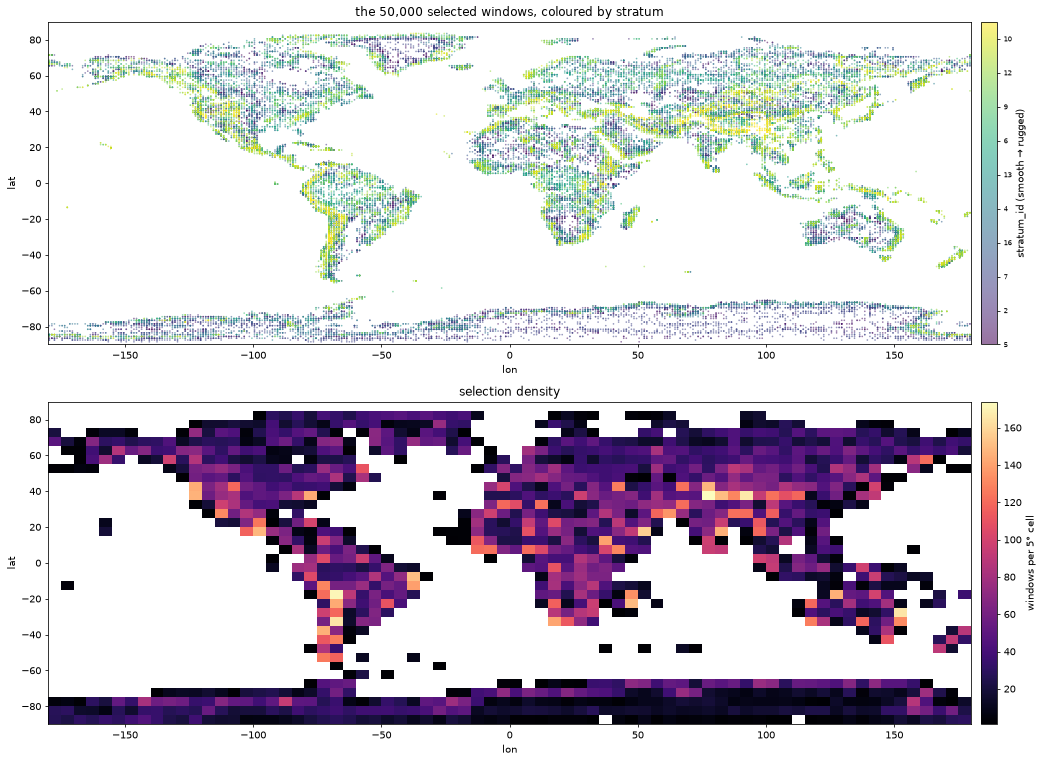

In [6]:
lon = np.array([stem_lonlat[s][0] for s in stems])
lat = np.array([stem_lonlat[s][1] for s in stems])

# Plot rugged strata last so they are not buried under the (far more numerous) flat ones.
rank_of = {h: r for r, h in enumerate(ORDER)}
draw_order = np.argsort([rank_of[h] for h in sel_stratum], kind="stable")

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(15, 11))

sc = ax0.scatter(lon[draw_order], lat[draw_order],
                 c=[rank_of[h] for h in sel_stratum[draw_order]],
                 cmap="viridis", s=3, alpha=0.55, linewidths=0)
cb = fig.colorbar(sc, ax=ax0, fraction=0.02, pad=0.01)
cb.set_ticks(range(0, K, 2))
cb.set_ticklabels([ORDER_LABELS[i] for i in range(0, K, 2)], fontsize=7)
cb.set_label("stratum_id (smooth → rugged)")
ax0.set(title=f"the {BUDGET:,} selected windows, coloured by stratum",
        xlabel="lon", ylabel="lat", xlim=(-180, 180), ylim=(-90, 90))

h2 = ax1.hist2d(lon, lat, bins=[np.arange(-180, 185, 5), np.arange(-90, 95, 5)],
                cmap="magma", cmin=1)
fig.colorbar(h2[3], ax=ax1, fraction=0.02, pad=0.01, label="windows per 5° cell")
ax1.set(title="selection density", xlabel="lon", ylabel="lat",
        xlim=(-180, 180), ylim=(-90, 90))

fig.tight_layout()
plt.show()

## 4 — The read path: tiles and per-tile normalization

The last two figures show the pixels themselves — what a model would actually ingest.
That needs a **materialized corpus** (int16 `shards/` + `manifest.parquet`), and the
end-to-end materialize is Phase E, not yet built. So this section constructs a
9-tile fixture directly from the ADR-0002 storage primitives, the same way
`tests/test_loader.py` does, and runs the real read path over it.

**The terrain is fabricated** — a seeded fractal field at nine relief/elevation
settings — so the *tiles* below are a demonstration of the mechanism, not corpus data.
Everything applied *to* them is live pipeline code, in the same order the real pipeline
applies it:

| step | live code |
|---|---|
| score the frozen six, each at its own resolution | `catalog.score_window` |
| transform + standardize with the committed scaler | `frame.metric_matrix`, `Scaler.standardize` |
| label with the nearest committed centroid | `centroids.assign` |
| clip, cast to int16 metres, take land-only stats | `normalize.prepare_tile` |
| append into a shard, write the manifest | `shards.ShardWriter`, `manifest` |
| read back, mask, normalize, batch | `loader.TileDataset` |

If you have a materialized corpus of your own — a Phase-E build, or one you made — set
`CORPUS_DIR` in the next cell to its path and every figure below re-renders against it
untouched.

In [7]:
from dataset import catalog, config, manifest, normalize, shards

#: Point this at a materialized corpus (`shards/` + `manifest.parquet` + `corpus_meta.json`)
#: to render that instead — a Phase-E build, or one you made yourself. `None` uses the
#: fixture below, which is what a fresh clone gets.
CORPUS_DIR = None
FIXTURE_DIR = REPO / "notebooks" / "data" / "loader_fixture"  # gitignored scratch


def fractal_terrain(rng, *, relief_m, base_m, sea_frac=0.0, px=config.TILE_PX, octaves=7):
    """A seeded fractal field standing in for terrain: summed bilinear-upsampled noise
    octaves, rescaled to a target relief and base elevation. Deterministic, numpy-only.

    ``sea_frac > 0`` floods that fraction of the field to **exactly 0.0** — Copernicus's
    ocean fill, and the value `dataset.screen` and the land mask are both defined
    against. Land then starts at ``base_m`` above the waterline.
    """
    field = np.zeros((px, px), dtype=np.float32)
    amplitude = 1.0
    for octave in range(octaves):
        n = 2 ** (octave + 1)
        grid = rng.normal(size=(n + 1, n + 1)).astype(np.float32)
        t = np.linspace(0, n, px)
        i0 = np.clip(np.floor(t).astype(int), 0, n - 1)
        frac = (t - i0).astype(np.float32)
        rowwise = grid[:, i0] * (1 - frac) + grid[:, i0 + 1] * frac       # (n+1, px)
        field += amplitude * (rowwise[i0] * (1 - frac[:, None])
                              + rowwise[i0 + 1] * frac[:, None])
        amplitude *= 0.55
    field -= field.min()
    field = field / max(field.max(), 1e-6) * relief_m
    if sea_frac <= 0.0:
        return (field + base_m).astype(np.float32)
    waterline = float(np.quantile(field, sea_frac))
    return np.where(field <= waterline, 0.0, field - waterline + base_m).astype(np.float32)


#: ``(relief m, base elevation m, sea fraction, lon, lat)`` — nine settings spanning a
#: polder to an alpine ridge, including one coastal window that is 40% ocean fill.
FIXTURE_SPECS = [
    (35, 15, 0.0, 4.5, 52.5), (75, 120, 0.0, -95.5, 41.5), (140, 260, 0.0, 8.5, 47.5),
    (260, 640, 0.0, -71.5, -13.5), (400, 40, 0.40, 138.5, 36.5), (620, 1450, 0.0, -106.5, 39.5),
    (900, 2600, 0.0, 86.5, 28.5), (1400, 900, 0.0, -73.5, -45.5), (2100, 4200, 0.0, 75.5, 35.5),
]


def build_fixture(out_dir):
    """Score → assign → prepare → shard → manifest, for each fabricated window."""
    rng = np.random.default_rng(config.RANDOM_SEED)
    windows, records = [], []
    scores = []
    for relief_m, base_m, sea_frac, lon_d, lat_d in FIXTURE_SPECS:
        win = fractal_terrain(rng, relief_m=relief_m, base_m=base_m, sea_frac=sea_frac)
        windows.append(win)
        # Exactly catalog.score_window's contract: the full-res window plus the ×8
        # overview covering the identical ground, each handed its own pixel spacing.
        # A 1° Copernicus COG is 3600 rows; its ×8 overview is 450.
        scores.append(catalog.score_window(
            win, win[::8, ::8], win_row0=0, win_col0=0,
            full_h=3600, full_w=3600, ov_h=450, ov_w=450, lat=lat_d,
        ))

    X = frame_mod.metric_matrix({m: np.array([s[m] for s in scores]) for m in METRICS})
    strata = centroids_mod.assign(scaler.standardize(X), centroids)

    gsum = gsumsq = gcount = 0.0
    with shards.ShardWriter(out_dir / "shards") as writer:
        for i, (win, (*_, lon_d, lat_d)) in enumerate(zip(windows, FIXTURE_SPECS)):
            # prepare_tile is the whole storage-side recipe: the zero-fill screen
            # (dataset.screen, ≥75% exact-zero → dropped), the ±plausibility clip, the
            # cast to int16 metres, and the land-only mean/std the loader normalizes by.
            tile, reason = normalize.prepare_tile(win)
            assert tile is not None, reason
            ref = writer.add(tile.raw_i16)
            land = tile.raw_i16[normalize.land_mask(tile.raw_i16)].astype(np.float64)
            gsum += float(land.sum()); gsumsq += float(np.square(land).sum()); gcount += land.size
            stem = geometry.format_cog_stem(int(np.floor(lon_d)), int(np.floor(lat_d)))
            records.append(manifest.TileRecord(
                tile_id=manifest.make_tile_id(stem, i * config.TILE_PX, 0),
                shard_id=ref.shard_id, row_index=ref.row_index,
                source_cog=f"{stem}/{stem}.tif",
                win_row0=i * config.TILE_PX, win_col0=0,
                lon=lon_d, lat=lat_d,
                lat_band=geometry.lat_band(lat_d), geocell_id=geometry.geocell_id(lon_d, lat_d),
                tri=float("nan"),                 # ADR-0001-era manifest column, unused here
                stratum=int(strata[i]),           # from centroids.assign, the live labeller
                mean=tile.mean, std=tile.std, land_frac=tile.land_frac,
                content_hash=ref.content_hash,
            ))
    gmean = gsum / gcount
    manifest.write_manifest(records, out_dir / "manifest.parquet")
    manifest.write_corpus_meta(
        out_dir / "corpus_meta.json", rows=records, global_mean=gmean,
        global_std=float(np.sqrt(max(gsumsq / gcount - gmean * gmean, 0.0))),
        snapshot_date="fixture", build_timestamp="1970-01-01T00:00:00Z",
        code_version="notebook-fixture",
    )
    return scores, strata


if CORPUS_DIR is not None:
    corpus_dir, source = Path(CORPUS_DIR), "materialized corpus"
else:
    corpus_dir, source = FIXTURE_DIR, "fabricated fixture"
    if not (FIXTURE_DIR / "manifest.parquet").exists():
        FIXTURE_DIR.mkdir(parents=True, exist_ok=True)
        fixture_scores, fixture_strata = build_fixture(FIXTURE_DIR)
        print(f"scored and assigned the fixture windows "
              f"(the zero-fill screen drops a window at ≥{config.LAND_ZERO_FRAC_DROP:.0%} "
              "exact-zero):")
        for (relief_m, base_m, sea, *_), sc, h in zip(FIXTURE_SPECS, fixture_scores,
                                                      fixture_strata):
            print(f"  relief {relief_m:>4} m, base {base_m:>4} m, ocean {sea:>4.0%}  →  "
                  f"slope {sc['slope_mean']:5.1f}°, relief {sc['local_relief']:6.0f} m, "
                  f"entropy {sc['geomorphon_entropy']:.2f}  →  stratum {h:>2}")

meta = json.loads((corpus_dir / "corpus_meta.json").read_text())
print(f"\ncorpus: {corpus_dir.relative_to(REPO)}  ({source})")
print(f"  dataset_version {meta['dataset_version']}  |  {meta['n_tiles']} tiles  |  "
      f"{meta['storage_dtype']}  |  normalization {meta['normalization']}")
print(f"  global land mean/std: {meta['global_mean']:.1f} / {meta['global_std']:.1f} m")

scored and assigned the fixture windows (the zero-fill screen drops a window at ≥75% exact-zero):
  relief   35 m, base   15 m, ocean   0%  →  slope   0.6°, relief     30 m, entropy 0.32  →  stratum  5
  relief   75 m, base  120 m, ocean   0%  →  slope   1.4°, relief     66 m, entropy 2.46  →  stratum  8
  relief  140 m, base  260 m, ocean   0%  →  slope   3.8°, relief    135 m, entropy 2.14  →  stratum  4
  relief  260 m, base  640 m, ocean   0%  →  slope   5.3°, relief    231 m, entropy 2.06  →  stratum  9
  relief  400 m, base   40 m, ocean  40%  →  slope   7.2°, relief    222 m, entropy 2.22  →  stratum 14
  relief  620 m, base 1450 m, ocean   0%  →  slope  14.6°, relief    534 m, entropy 2.04  →  stratum 10
  relief  900 m, base 2600 m, ocean   0%  →  slope  18.6°, relief    732 m, entropy 2.07  →  stratum 10
  relief 1400 m, base  900 m, ocean   0%  →  slope  27.0°, relief   1258 m, entropy 1.92  →  stratum  1
  relief 2100 m, base 4200 m, ocean   0%  →  slope  36.3°, relief   18

### Sampled tiles, mean-centred on one scale

Each tile is **mean-centred** (its own land mean subtracted) and drawn on a **single
shared colour scale**, so absolute altitude is removed and every panel is directly
comparable: a flat tile stays near its zero mean (muted, near-uniform) while a rugged
one swings across the full scale.

> **Why mean-centre and share the scale?** `imshow` otherwise autoscales each panel to
> its own min/max, so a nearly-flat 20 m tile and an 800 m mountain get the identical
> colour span — flat looks dramatic, rugged looks like flat speckle. Removing the
> altitude offset lets one universal scale show the difference.

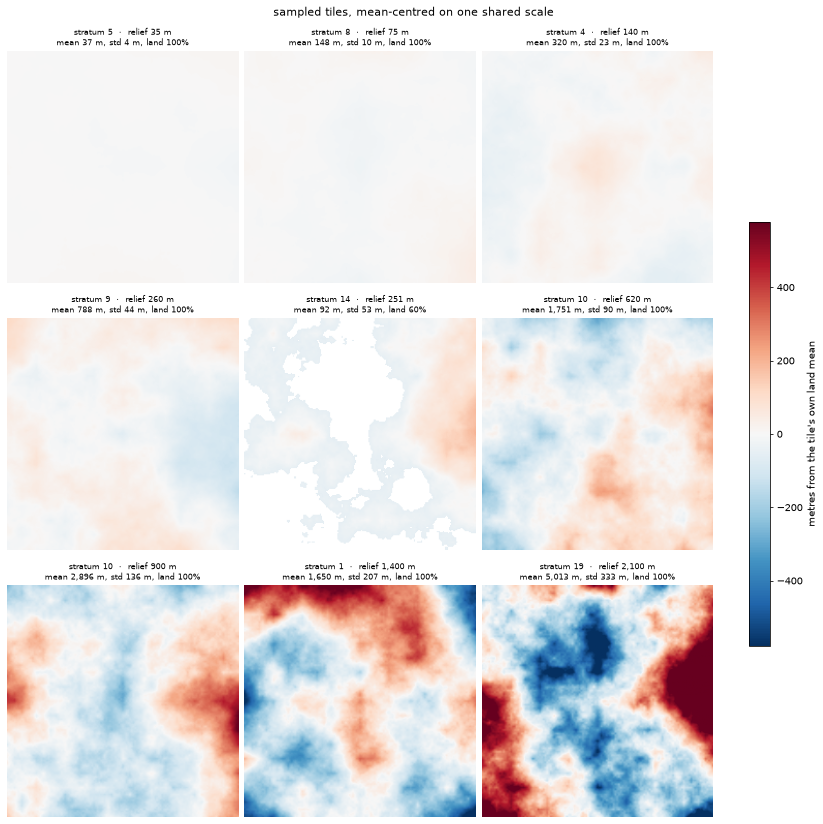

In [8]:
import pyarrow.parquet as pq

table = pq.read_table(corpus_dir / "manifest.parquet")
cols = {name: table.column(name).to_numpy(zero_copy_only=False) for name in table.column_names}
n_tiles = table.num_rows
shard_memmaps = {}


def read_tile(i):
    """Raw int16 (224×224) elevation tile for manifest row i — the loader's own resolve."""
    sid = int(cols["shard_id"][i])
    mm = shard_memmaps.get(sid)
    if mm is None:
        mm = np.load(shards.shard_path(corpus_dir / "shards", sid), mmap_mode="r")
        shard_memmaps[sid] = mm
    return mm[int(cols["row_index"][i])]


picks = np.argsort(cols["std"])[np.linspace(0, n_tiles - 1, min(9, n_tiles)).astype(int)]
centered, relief = {}, {}
for i in picks:
    tile = read_tile(i).astype(np.float32)
    land = normalize.land_mask(tile)
    centered[i] = np.where(land, tile - tile[land].mean(), np.nan)
    relief[i] = float(tile[land].max() - tile[land].min()) if land.any() else 0.0

# One universal, symmetric scale: a robust percentile of the pooled deviations, so flat
# tiles read muted and rugged ones saturate.
pooled = np.concatenate([np.abs(c[np.isfinite(c)]) for c in centered.values()])
vlim = float(np.percentile(pooled, 99))

ncol = 3
nrow = int(np.ceil(len(picks) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.9 * ncol, 3.9 * nrow), layout="constrained")
axes = np.atleast_2d(axes)
for ax, i in zip(axes.ravel(), picks):
    im = ax.imshow(centered[i], cmap="RdBu_r", vmin=-vlim, vmax=vlim)
    ax.set_title(f"stratum {int(cols['stratum'][i])}  ·  relief {relief[i]:,.0f} m\n"
                 f"mean {cols['mean'][i]:,.0f} m, std {cols['std'][i]:,.0f} m, "
                 f"land {cols['land_frac'][i]:.0%}", fontsize=8)
    ax.axis("off")
for ax in axes.ravel()[len(picks):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.03, label="metres from the tile's own land mean")
fig.suptitle("sampled tiles, mean-centred on one shared scale", fontsize=11)
plt.show()

### Before / after per-tile normalization

The default normalization is **per-tile standardization**: subtract the tile's
land-only mean, divide by its land-only std — both stored in the manifest so the
transform is invertible. This teaches the model *terrain shape* invariant to absolute
altitude. The land mask is derived from the raw int16 (`raw != 0`) *before*
normalization, which is why it survives a transform that would otherwise move the
ocean fill off zero.

The rows below come out of `loader.TileDataset` itself — the real Phase-1 read path,
batched through `build_dataloader` — rather than being recomputed here.

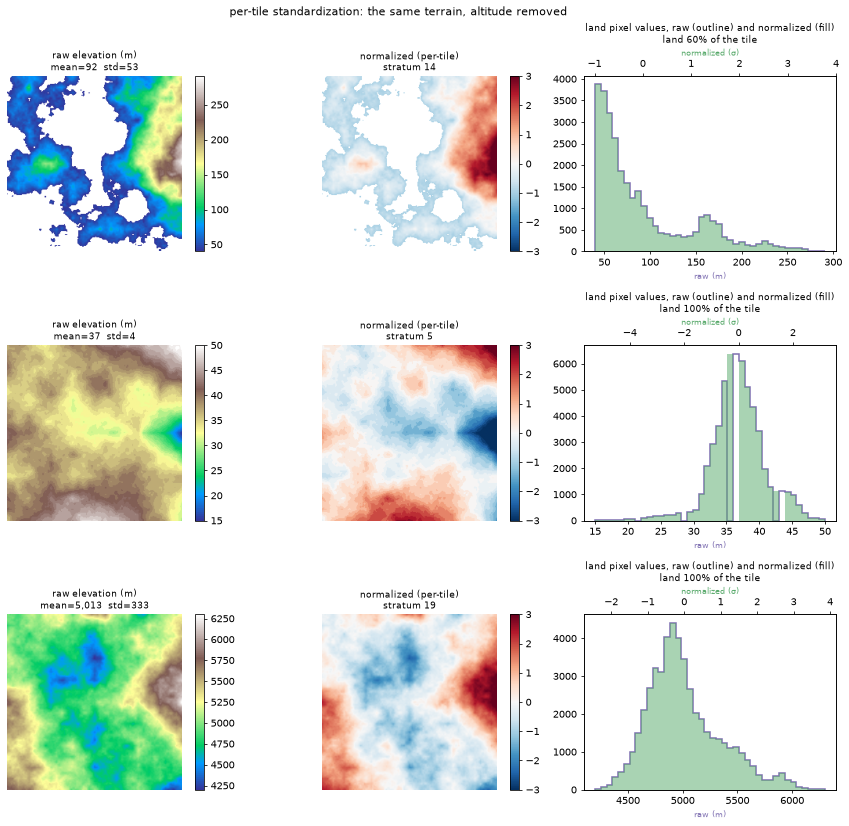

In [9]:
from dataset import loader

ds = loader.TileDataset(corpus_dir, normalization="per_tile")
# The most ocean-covered tile (so the land mask has something to do), plus the extremes
# of absolute altitude (so "altitude removed" is visible as a change).
show = list(dict.fromkeys(int(i) for i in (np.argmin(cols["land_frac"]),
                                           np.argmin(cols["mean"]),
                                           np.argmax(cols["mean"]))))

fig, axes = plt.subplots(len(show), 3, figsize=(13, 4 * len(show)))
axes = np.atleast_2d(axes)
for row, i in enumerate(show):
    sample = ds[i]
    mask = sample["land_mask"].numpy()
    norm = sample["image"][0].numpy()
    raw = read_tile(i).astype(np.float32)
    mean, std = float(sample["mean"]), float(sample["std"])

    im0 = axes[row, 0].imshow(np.where(mask, raw, np.nan), cmap="terrain")
    axes[row, 0].set_title(f"raw elevation (m)\nmean={mean:,.0f}  std={std:,.0f}", fontsize=9)
    axes[row, 0].axis("off"); fig.colorbar(im0, ax=axes[row, 0], fraction=0.046)

    im1 = axes[row, 1].imshow(np.where(mask, norm, np.nan), cmap="RdBu_r", vmin=-3, vmax=3)
    axes[row, 1].set_title(f"normalized (per-tile)\nstratum {sample['stratum']}", fontsize=9)
    axes[row, 1].axis("off"); fig.colorbar(im1, ax=axes[row, 1], fraction=0.046)

    axes[row, 2].hist(raw[mask], bins=40, histtype="step", lw=1.6, color="#8172b3")
    axes[row, 2].set_xlabel("raw (m)", color="#8172b3", fontsize=8)
    twin = axes[row, 2].twiny()
    twin.hist(norm[mask], bins=40, color="#55a868", alpha=0.5)
    twin.set_xlabel("normalized (σ)", color="#55a868", fontsize=8)
    # One distribution, two axes: standardization is affine, so the *shape* is untouched
    # — only the units under it change, from metres to σ.
    axes[row, 2].set_title(f"land pixel values, raw (outline) and normalized (fill)\n"
                           f"land {cols['land_frac'][i]:.0%} of the tile", fontsize=9)

fig.suptitle("per-tile standardization: the same terrain, altitude removed", fontsize=11)
fig.tight_layout()
plt.show()

In [10]:
batch = next(iter(loader.build_dataloader(ds, batch_size=4, num_workers=0)))
land = batch["image"][:, 0][batch["land_mask"]]
print(f"one batch: image {tuple(batch['image'].shape)} {batch['image'].dtype}, "
      f"land_mask {tuple(batch['land_mask'].shape)}")
print(f"land pixels over the batch: mean {land.mean():+.3f}, std {land.std():.3f} "
      "(per-tile standardization, so ≈ 0 / 1)")

one batch: image (4, 1, 224, 224) torch.float32, land_mask (4, 224, 224)
land pixels over the batch: mean -0.000, std 1.000 (per-tile standardization, so ≈ 0 / 1)


/Users/jstoschek/Code/DEMMAE/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


---

**Reproduce this.** Sections 1–3 need nothing but this repo: the scaler, the centroids
and the selection list are committed artifacts, and the numbers plotted are re-derived
from them by the live `dataset.*` code every time the notebook runs. Section 4's
fixture is seeded and rebuilds identically.

To regenerate the artifacts themselves — hours, and the only stage that touches the
network is the first:

```bash
uv run python -m dataset.catalog     # the global ×8-overview scoring pass
uv run python -m dataset.gates       # the locked quality gates
uv run python -m dataset.frame       # fit + persist the scaler        (#40)
uv run python -m dataset.centroids   # fit + persist the k=20 centroids (#41)
uv run python -m dataset.select      # allocate + FSCS → the selection list (#44)
```

Cover sheets: [`docs/research/d1-stratification-frame.md`](../docs/research/d1-stratification-frame.md),
[`d1-choose-k.md`](../docs/research/d1-choose-k.md),
[`d2-allocation.md`](../docs/research/d2-allocation.md),
[`d3-fscs-cost.md`](../docs/research/d3-fscs-cost.md),
[`d4-sampler.md`](../docs/research/d4-sampler.md).